In [ ]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
import torch as th
from stable_baselines3 import DQN
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.vec_env import DummyVecEnv

from rainbow_dqn import RainbowDQN, DuelingDQNPolicy
from replay_buffer import PrioritizedReplayBuffer

In [ ]:
# ── Constants ─────────────────────────────────────────────────────────────────

SEED        = 42
N_EPOCHS    = 30
N_EVAL_ENVS = 20   # parallel envs for eval at each epoch checkpoint

ENVS = {
    "CartPole-v1":    dict(total_steps= 50_000),
    "Acrobot-v1":     dict(total_steps=150_000),
    "MountainCar-v0": dict(total_steps=400_000),
    "Taxi-v3":        dict(total_steps=400_000),
}

# ── Shared hyperparams — identical for both models in every section ───────────

SHARED_KWARGS = dict(
    policy_kwargs           = dict(net_arch=[128, 128]),
    learning_rate           = 1e-4,
    batch_size              = 64,
    gamma                   = 0.99,
    learning_starts         = 1_000,
    buffer_size             = 50_000,
    target_update_interval  = 1_000,
    tau                     = 1.0,
    train_freq              = 4,
    gradient_steps          = 1,
    exploration_fraction    = 0.15,
    exploration_initial_eps = 1.0,
    exploration_final_eps   = 0.05,
    max_grad_norm           = 10,
    verbose                 = 0,
)

# ── Training helper ───────────────────────────────────────────────────────────

def train_epochs_vec(model, env_id, total_steps, invariant_fn=None):
    """
    Train model in N_EPOCHS equal intervals.
    Eval after each epoch using N_EVAL_ENVS parallel envs.
    Returns (rewards, invariants) — invariants is [] when invariant_fn is None.
    """
    eval_env        = DummyVecEnv([lambda: gym.make(env_id)] * N_EVAL_ENVS)
    steps_per_epoch = max(1, total_steps // N_EPOCHS)
    rewards, invariants = [], []

    for i in range(N_EPOCHS):
        model.learn(
            total_timesteps     = steps_per_epoch,
            reset_num_timesteps = (i == 0),
            progress_bar        = False,
        )
        mean_r, _ = evaluate_policy(
            model, eval_env,
            n_eval_episodes = N_EVAL_ENVS,
            deterministic   = True,
        )
        rewards.append(mean_r)
        if invariant_fn is not None:
            invariants.append(invariant_fn(model))

    eval_env.close()
    return rewards, invariants


# ── Plotting helper ────────────────────────────────────────────────────────────

def _smooth(arr, w):
    """Centred rolling mean with window w; edges use available data (no padding)."""
    arr = np.asarray(arr, dtype=float)
    out = np.full_like(arr, np.nan)
    half = w // 2
    for i in range(len(arr)):
        lo = max(0, i - half)
        hi = min(len(arr), i + half + 1)
        out[i] = arr[lo:hi].mean()
    return out


def plot_section(title, env_results, label_a, label_b,
                 inv_label=None, colors=("steelblue", "orangered"), smooth=5):
    """
    env_results: list of dicts with env_id, rewards_a, rewards_b,
                 and optionally invs_a, invs_b.

    smooth: rolling-window width for the solid overlay (raw data shown faint).
            Set to 1 or None to disable.
    """
    has_inv = inv_label is not None and "invs_a" in env_results[0]
    n_cols  = 2 if has_inv else 1
    fig, axes = plt.subplots(
        len(env_results), n_cols,
        figsize=(6 * n_cols, 3.2 * len(env_results)),
        squeeze=False,
    )
    fig.suptitle(title, fontsize=13, fontweight="bold")
    w = smooth if (smooth and smooth > 1) else None

    for row, res in enumerate(env_results):
        env_id = res["env_id"]
        steps  = (np.arange(1, N_EPOCHS + 1)
                  * (ENVS[env_id]["total_steps"] // N_EPOCHS))

        def _plot(ax, ya, yb, ylabel):
            if w:
                ax.plot(steps, ya, alpha=0.2, color=colors[0], lw=1)
                ax.plot(steps, yb, alpha=0.2, color=colors[1], lw=1)
                ax.plot(steps, _smooth(ya, w), label=label_a, color=colors[0], lw=2)
                ax.plot(steps, _smooth(yb, w), label=label_b, color=colors[1], lw=2)
            else:
                ax.plot(steps, ya, label=label_a, color=colors[0], lw=2)
                ax.plot(steps, yb, label=label_b, color=colors[1], lw=2)
            ax.set_ylabel(ylabel)
            ax.legend(fontsize=8)
            ax.grid(True, alpha=0.3)

        ax = axes[row, 0]
        _plot(ax, res["rewards_a"], res["rewards_b"], "Mean reward")
        ax.set_title(env_id)
        if row == len(env_results) - 1:
            ax.set_xlabel("Env steps")

        if has_inv:
            ax2 = axes[row, 1]
            _plot(ax2, res["invs_a"], res["invs_b"], inv_label)
            ax2.set_title(f"{env_id}  —  {inv_label}")
            if row == len(env_results) - 1:
                ax2.set_xlabel("Env steps")

    plt.tight_layout()
    plt.show()


# ── Invariant functions ────────────────────────────────────────────────────────

def _get_batch(model, size=512):
    """Sample a batch from the replay buffer; return None if not enough data."""
    buf = model.replay_buffer
    if (buf.full and buf.buffer_size >= size) or (not buf.full and buf.pos >= size):
        try:
            return buf.sample(size)
        except Exception:
            pass
    return None


def inv_overestimation_gap(model):
    """
    Double DQN — E[max_a Q_target(s')] − E[Q_target(s', argmax Q_online(s'))].
    Positive value = online net overestimates; Double DQN drives this toward 0.
    """
    batch = _get_batch(model)
    if batch is None:
        return float("nan")
    with th.no_grad():
        q_on = model.q_net(batch.next_observations)
        q_tg = model.q_net_target(batch.next_observations)
    naive  = q_tg.max(dim=1).values.mean().item()
    double = q_tg.gather(1, q_on.argmax(dim=1, keepdim=True)).squeeze(1).mean().item()
    return naive - double


def inv_advantage_std(model):
    """
    Dueling — mean std of A(s,a) across actions over a batch.
    For DuelingQNetwork: reads adv_head directly.
    For MlpPolicy: uses Q(s,a) − mean_a Q(s,a) as a proxy.
    Non-zero = network meaningfully differentiates action quality.
    """
    batch = _get_batch(model)
    if batch is None:
        return float("nan")
    q_net = model.q_net
    with th.no_grad():
        if hasattr(q_net, "adv_head"):
            feats = q_net.q_net(
                q_net.extract_features(batch.observations, q_net.features_extractor)
            )
            adv = q_net.adv_head(feats)
        else:
            q   = q_net(batch.observations)
            adv = q - q.mean(dim=1, keepdim=True)
    return adv.std(dim=1).mean().item()


def inv_priority_cv(model):
    """
    PER — coefficient of variation of leaf priorities in the SumTree.
    CV = std / mean.  0 = uniform (no prioritization); grows as PER focuses.
    """
    buf = model.replay_buffer
    if not isinstance(buf, PrioritizedReplayBuffer):
        return float("nan")
    n      = buf.buffer_size if buf.full else buf.pos
    leaves = buf.sum_tree.tree[buf.sum_tree.capacity - 1 :
                               buf.sum_tree.capacity - 1 + n]
    leaves = leaves[leaves > 0]
    if len(leaves) < 2:
        return 0.0
    return float(leaves.std() / leaves.mean())


def inv_mean_abs_reward(model):
    """
    n-step — mean |reward| in the replay buffer.
    n-step accumulates r_t + γr_{t+1} + … so this grows vs 1-step baseline.
    """
    batch = _get_batch(model)
    if batch is None:
        return float("nan")
    return batch.rewards.abs().mean().item()

  CartPole-v1 ... done
  Acrobot-v1 ... done
  MountainCar-v0 ... done
  Taxi-v3 ... done


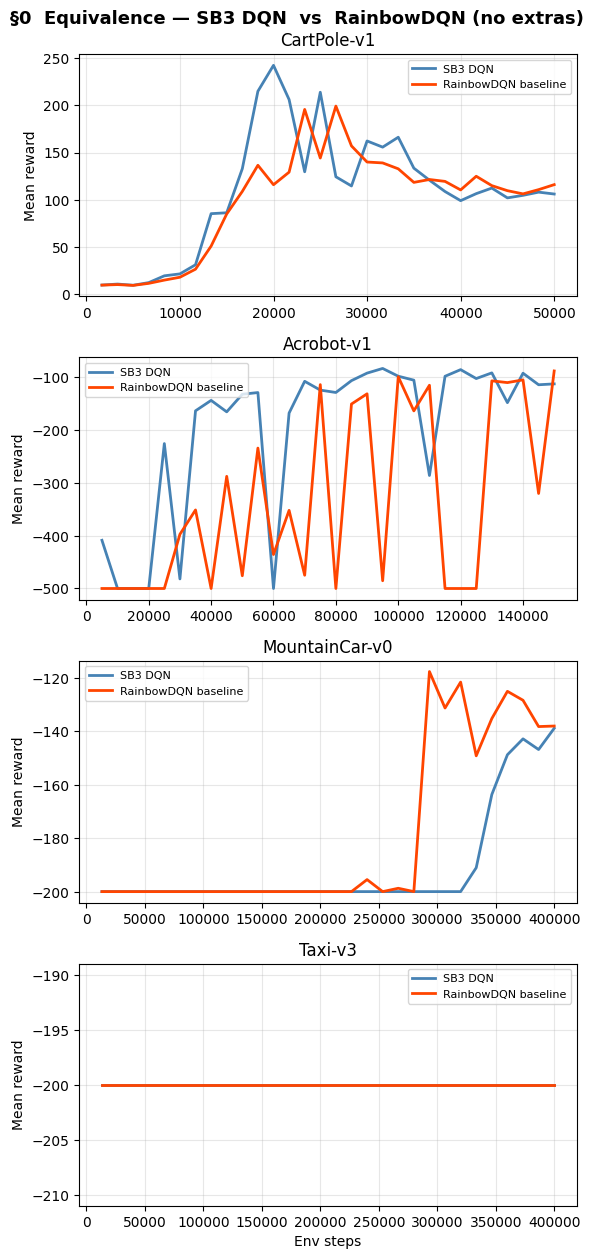

In [17]:

# ══════════════════════════════════════════════════════════════════════════════
# §0  EQUIVALENCE  —  SB3 DQN  ≡  RainbowDQN (baseline)
# ══════════════════════════════════════════════════════════════════════════════
# Both models: MlpPolicy, standard ReplayBuffer, n_steps=1, no Double DQN.
# If curves overlap: our train() is a faithful re-implementation of SB3's.
# If they diverge: there is a bug in the base loop before any Rainbow component.

env_results = []
for env_id, meta in ENVS.items():
    print(f"  {env_id} ...", end=" ", flush=True)

    sb3_model = DQN(
        policy = "MlpPolicy",
        env    = gym.make(env_id),
        seed   = SEED,
        **SHARED_KWARGS,
    )
    our_model = RainbowDQN(
        policy         = "MlpPolicy",
        env            = gym.make(env_id),
        seed           = SEED,
        use_double_dqn = False,   # SB3 DQN uses max Q_target (not Double DQN)
        n_steps        = 1,
        **SHARED_KWARGS,
    )

    rew_a, _ = train_epochs_vec(sb3_model, env_id, meta["total_steps"])
    rew_b, _ = train_epochs_vec(our_model, env_id, meta["total_steps"])
    env_results.append(dict(env_id=env_id, rewards_a=rew_a, rewards_b=rew_b))
    print("done")

plot_section(
    "§0  Equivalence — SB3 DQN  vs  RainbowDQN (no extras)",
    env_results,
    label_a = "SB3 DQN",
    label_b = "RainbowDQN baseline",
)


  CartPole-v1 ... done
  Acrobot-v1 ... done
  MountainCar-v0 ... done
  Taxi-v3 ... done


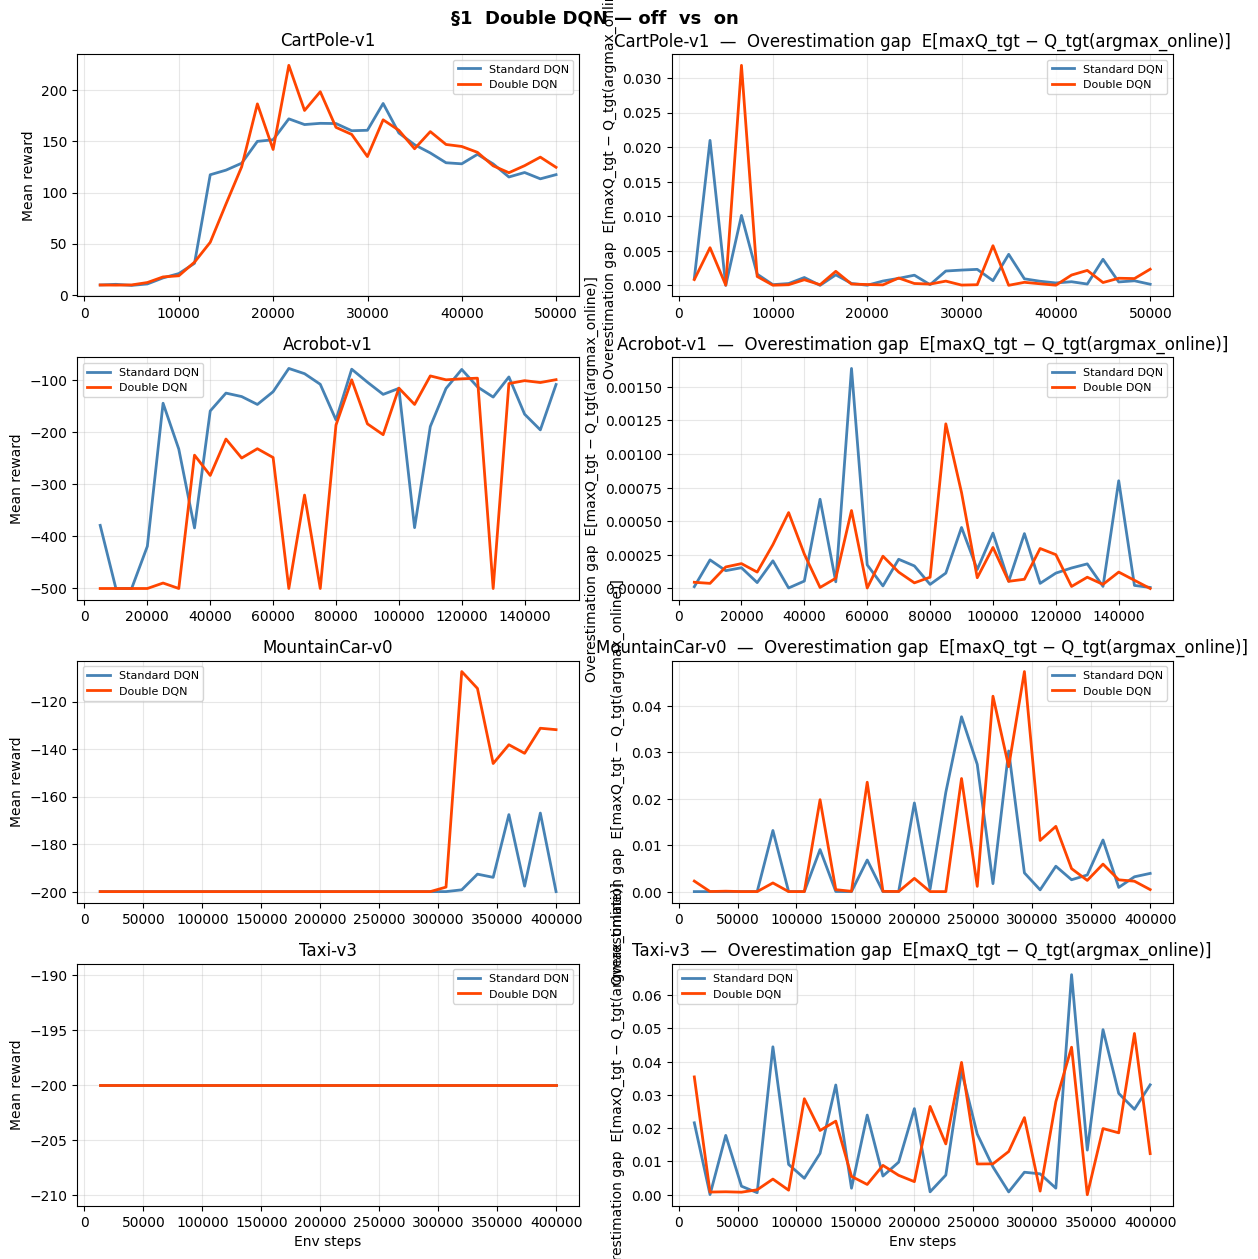

In [18]:

# ══════════════════════════════════════════════════════════════════════════════
# §1  DOUBLE DQN
# ══════════════════════════════════════════════════════════════════════════════
# Toggle: use_double_dqn=False  vs  use_double_dqn=True.  All else identical.
#
# Invariant (van Hasselt 2016):
#   gap = E[max_a Q_target(s')] − E[Q_target(s', argmax Q_online(s'))]
#   Standard DQN: gap > 0  (online net overestimates bootstrap target)
#   Double DQN:   gap ≈ 0  (decoupled selection/evaluation kills the bias)
#
# Expected: reward curves similar or better for Double DQN; gap clearly lower.

env_results = []
for env_id, meta in ENVS.items():
    print(f"  {env_id} ...", end=" ", flush=True)

    model_a = RainbowDQN(
        policy="MlpPolicy", env=gym.make(env_id), seed=SEED,
        use_double_dqn=False, n_steps=1, **SHARED_KWARGS,
    )
    model_b = RainbowDQN(
        policy="MlpPolicy", env=gym.make(env_id), seed=SEED,
        use_double_dqn=True,  n_steps=1, **SHARED_KWARGS,
    )

    rew_a, inv_a = train_epochs_vec(model_a, env_id, meta["total_steps"], inv_overestimation_gap)
    rew_b, inv_b = train_epochs_vec(model_b, env_id, meta["total_steps"], inv_overestimation_gap)
    env_results.append(dict(env_id=env_id,
                            rewards_a=rew_a, rewards_b=rew_b,
                            invs_a=inv_a,    invs_b=inv_b))
    print("done")

plot_section(
    "§1  Double DQN — off  vs  on",
    env_results,
    label_a   = "Standard DQN",
    label_b   = "Double DQN",
    inv_label = "Overestimation gap  E[maxQ_tgt − Q_tgt(argmax_online)]",
)


  CartPole-v1 ... done
  Acrobot-v1 ... done
  MountainCar-v0 ... done
  Taxi-v3 ... done


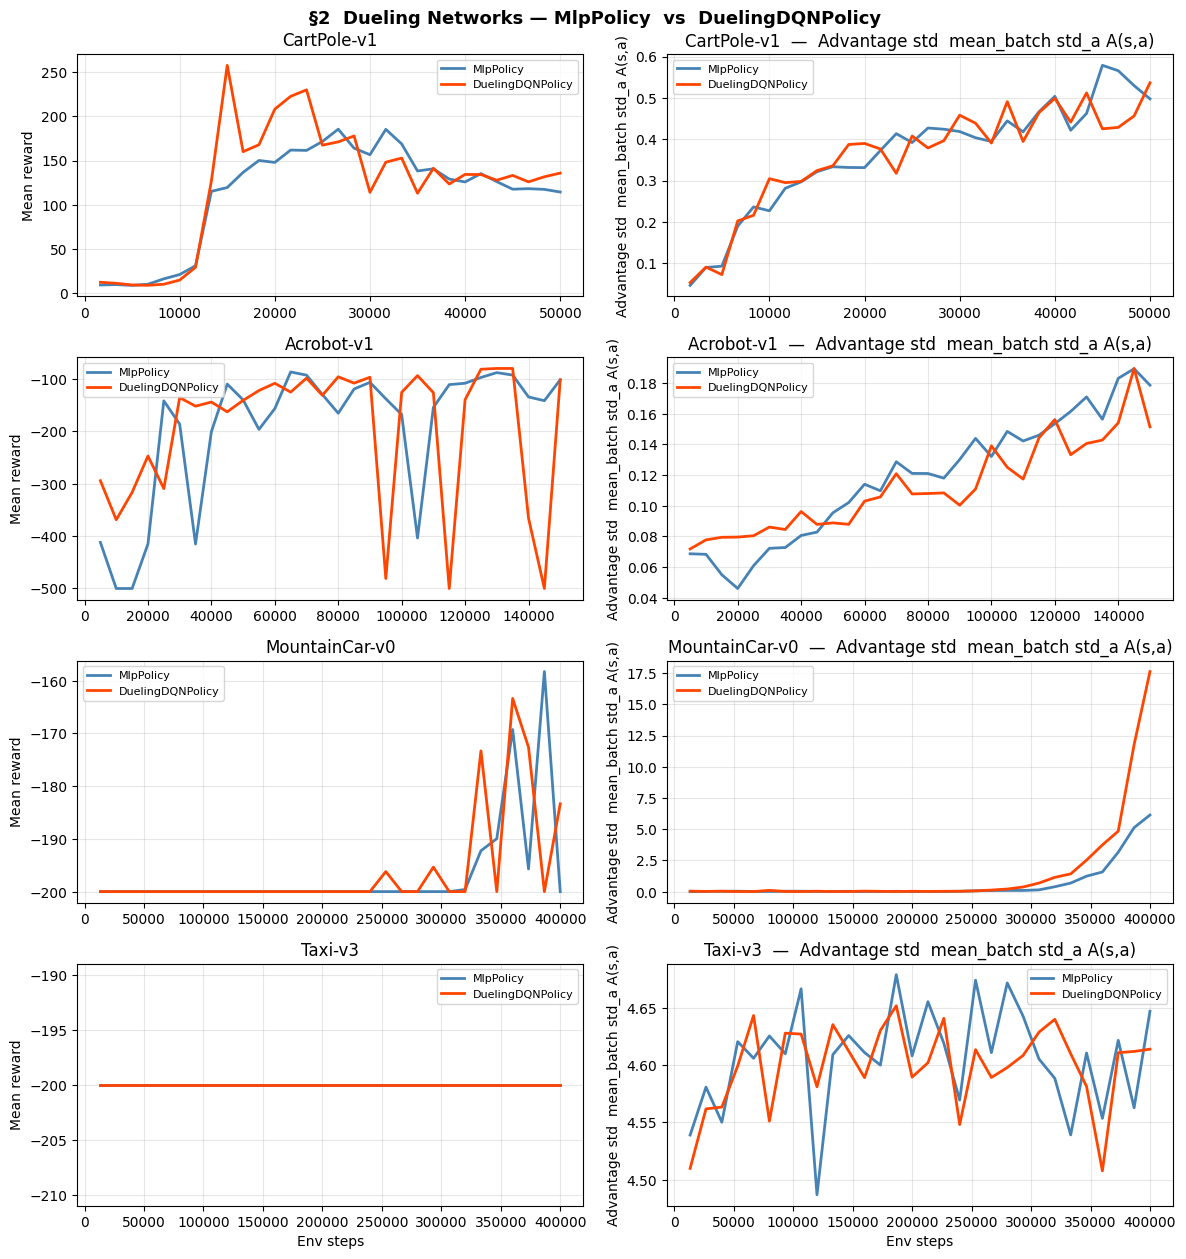

In [19]:

# ══════════════════════════════════════════════════════════════════════════════
# §2  DUELING NETWORKS
# ══════════════════════════════════════════════════════════════════════════════
# Toggle: "MlpPolicy"  vs  DuelingDQNPolicy.  All else identical.
#
# Invariant (Wang et al. 2016):
#   std_A = mean over batch of std_a A(s,a)
#   For MlpPolicy: proxy = std_a [Q(s,a) − mean_a Q(s,a)]
#   Dueling explicitly learns V(s) and A(s,a) in separate heads.
#   If the decomposition is working, std_A should be meaningful and distinct
#   from the MlpPolicy proxy — especially in states where action choice matters.
#
# Expected: comparable or better reward; dueling shows cleaner advantage signal
#   particularly on envs with many irrelevant states (Acrobot, MountainCar).

env_results = []
for env_id, meta in ENVS.items():
    print(f"  {env_id} ...", end=" ", flush=True)

    model_a = RainbowDQN(
        policy="MlpPolicy",    env=gym.make(env_id), seed=SEED,
        use_double_dqn=False, n_steps=1, **SHARED_KWARGS,
    )
    model_b = RainbowDQN(
        policy=DuelingDQNPolicy, env=gym.make(env_id), seed=SEED,
        use_double_dqn=False, n_steps=1, **SHARED_KWARGS,
    )

    rew_a, inv_a = train_epochs_vec(model_a, env_id, meta["total_steps"], inv_advantage_std)
    rew_b, inv_b = train_epochs_vec(model_b, env_id, meta["total_steps"], inv_advantage_std)
    env_results.append(dict(env_id=env_id,
                            rewards_a=rew_a, rewards_b=rew_b,
                            invs_a=inv_a,    invs_b=inv_b))
    print("done")

plot_section(
    "§2  Dueling Networks — MlpPolicy  vs  DuelingDQNPolicy",
    env_results,
    label_a   = "MlpPolicy",
    label_b   = "DuelingDQNPolicy",
    inv_label = "Advantage std  mean_batch std_a A(s,a)",
)


  CartPole-v1 ... done
  Acrobot-v1 ... done
  MountainCar-v0 ... done
  Taxi-v3 ... done


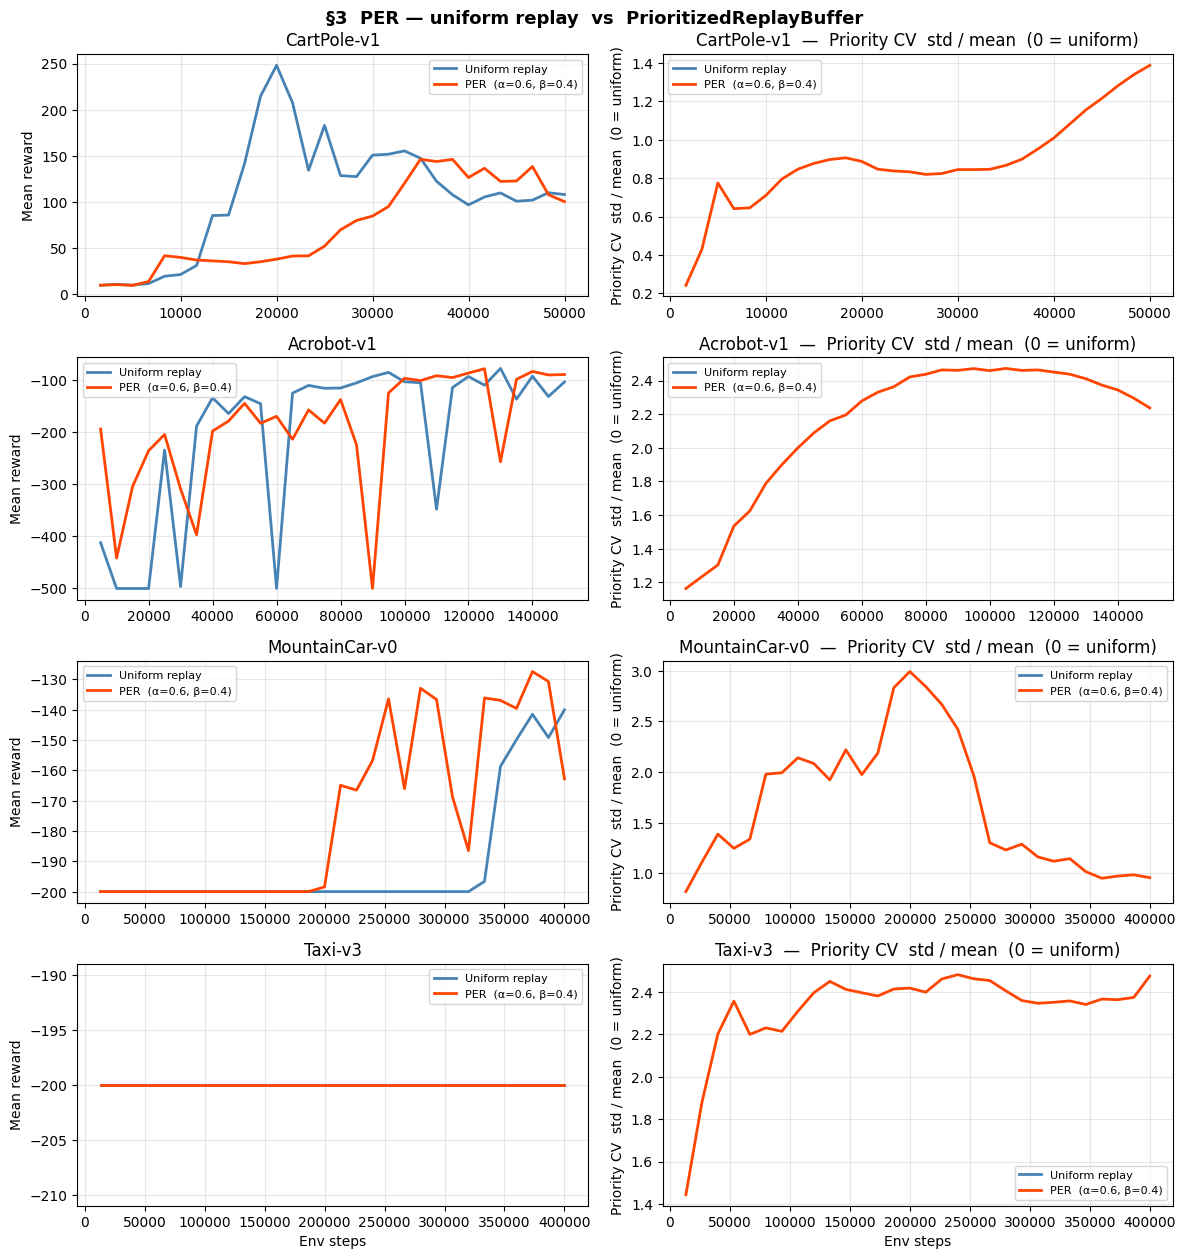

In [20]:

# ══════════════════════════════════════════════════════════════════════════════
# §3  PRIORITIZED EXPERIENCE REPLAY
# ══════════════════════════════════════════════════════════════════════════════
# Toggle: standard ReplayBuffer  vs  PrioritizedReplayBuffer.  All else identical.
#
# Invariant (Schaul et al. 2016):
#   CV(priorities) = std(leaf_priorities) / mean(leaf_priorities)
#   Uniform buffer: all priorities equal → CV ≈ 0.
#   PER: high-TD transitions accumulate higher priority → CV grows.
#   If PER is working correctly, CV should be clearly > 0 and grow over training.
#
# Expected: faster initial learning on envs with sparse reward (MountainCar);
#   priority CV grows as the agent discovers high-error transitions.

env_results = []
for env_id, meta in ENVS.items():
    print(f"  {env_id} ...", end=" ", flush=True)

    model_a = RainbowDQN(
        policy="MlpPolicy", env=gym.make(env_id), seed=SEED,
        use_double_dqn=False, n_steps=1, **SHARED_KWARGS,
    )
    model_b = RainbowDQN(
        policy="MlpPolicy", env=gym.make(env_id), seed=SEED,
        use_double_dqn    = False,
        n_steps           = 1,
        replay_buffer_class = PrioritizedReplayBuffer,
        per_alpha         = 0.6,
        per_beta          = 0.4,
        per_epsilon       = 1e-6,
        per_total_samples = 500_000,
        **SHARED_KWARGS,
    )

    rew_a, inv_a = train_epochs_vec(model_a, env_id, meta["total_steps"], inv_priority_cv)
    rew_b, inv_b = train_epochs_vec(model_b, env_id, meta["total_steps"], inv_priority_cv)
    env_results.append(dict(env_id=env_id,
                            rewards_a=rew_a, rewards_b=rew_b,
                            invs_a=inv_a,    invs_b=inv_b))
    print("done")

plot_section(
    "§3  PER — uniform replay  vs  PrioritizedReplayBuffer",
    env_results,
    label_a   = "Uniform replay",
    label_b   = "PER  (α=0.6, β=0.4)",
    inv_label = "Priority CV  std / mean  (0 = uniform)",
)


  CartPole-v1 ... done
  Acrobot-v1 ... done
  MountainCar-v0 ... done
  Taxi-v3 ... done


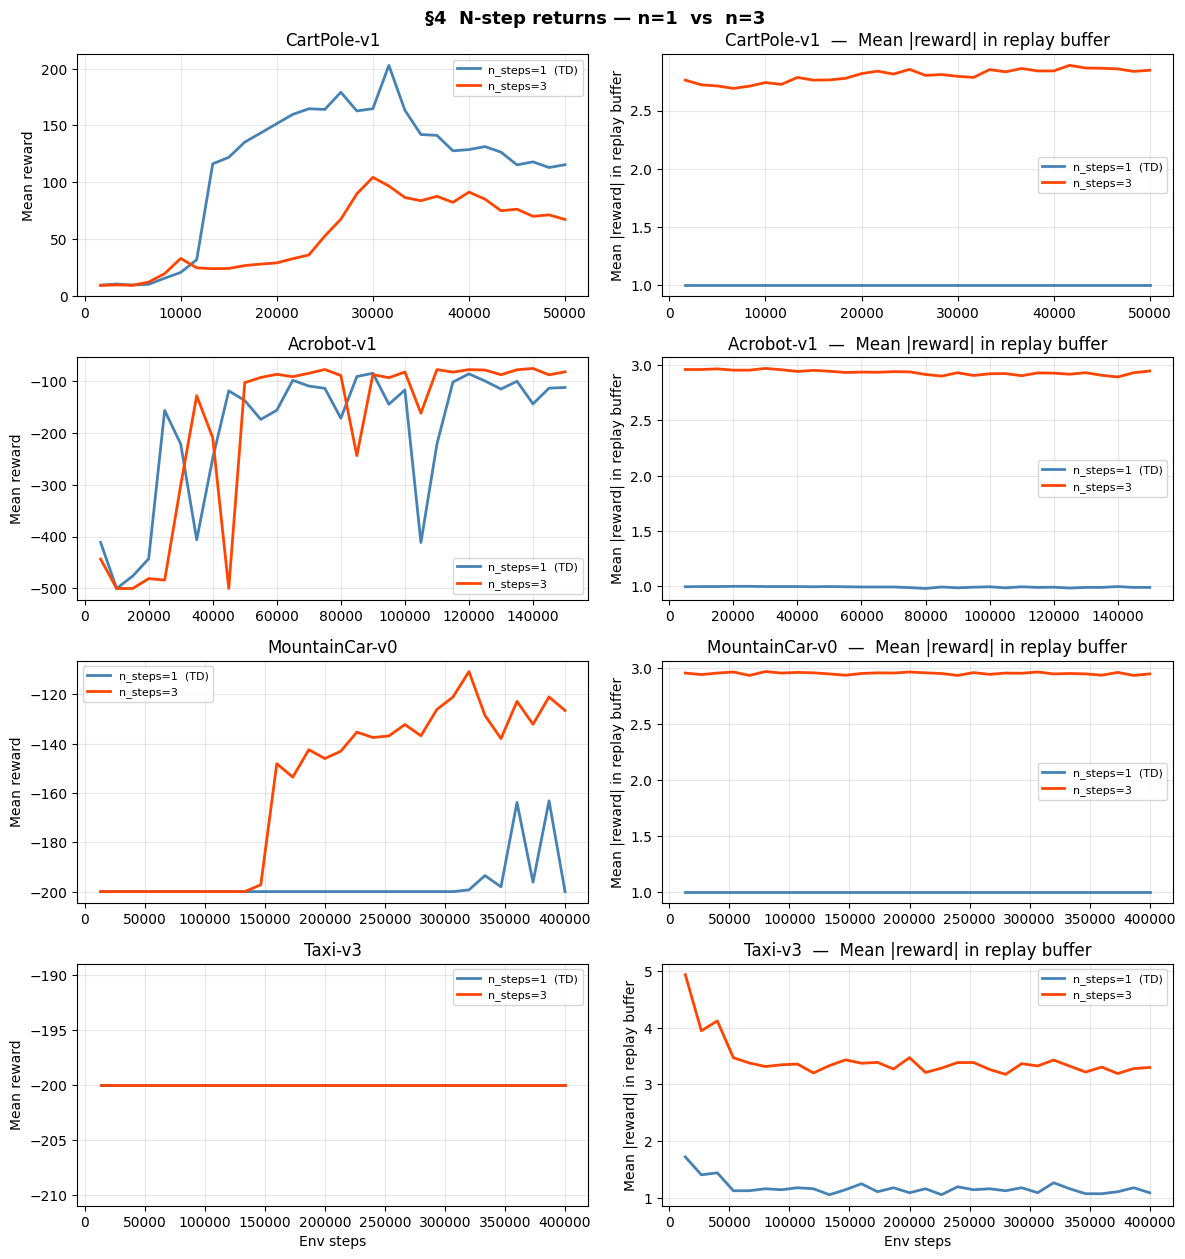

In [21]:

# ══════════════════════════════════════════════════════════════════════════════
# §4  N-STEP RETURNS
# ══════════════════════════════════════════════════════════════════════════════
# Toggle: n_steps=1  vs  n_steps=3.  All else identical.
#
# Invariant (Sutton 1988):
#   mean |reward| stored in the replay buffer.
#   n-step accumulates r_t + γr_{t+1} + γ²r_{t+2} before storing, so the
#   stored reward should be strictly larger in magnitude than 1-step.
#   If our NStepReplayBuffer wrapping is correct, the n=3 model's buffer
#   should consistently show higher mean |reward| than n=1.
#
# Expected: n-step reward curve leads in envs with delayed reward (Acrobot,
#   MountainCar); mean |reward| in buffer is visibly higher for n=3.

env_results = []
for env_id, meta in ENVS.items():
    print(f"  {env_id} ...", end=" ", flush=True)

    model_a = RainbowDQN(
        policy="MlpPolicy", env=gym.make(env_id), seed=SEED,
        use_double_dqn=False, n_steps=1, **SHARED_KWARGS,
    )
    model_b = RainbowDQN(
        policy="MlpPolicy", env=gym.make(env_id), seed=SEED,
        use_double_dqn=False, n_steps=3, **SHARED_KWARGS,
    )

    rew_a, inv_a = train_epochs_vec(model_a, env_id, meta["total_steps"], inv_mean_abs_reward)
    rew_b, inv_b = train_epochs_vec(model_b, env_id, meta["total_steps"], inv_mean_abs_reward)
    env_results.append(dict(env_id=env_id,
                            rewards_a=rew_a, rewards_b=rew_b,
                            invs_a=inv_a,    invs_b=inv_b))
    print("done")

plot_section(
    "§4  N-step returns — n=1  vs  n=3",
    env_results,
    label_a   = "n_steps=1  (TD)",
    label_b   = "n_steps=3",
    inv_label = "Mean |reward| in replay buffer",
)
